# EN3160 - Assignment 02: Fitting and Alignment

**Name:** Ahamed A.M.S   
**Index number:** 230020R  
**GitHub profile:** https://github.com/shaahidahamed


In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import blob_log, blob_dog
from matplotlib.patches import Circle
from scipy.optimize import least_squares

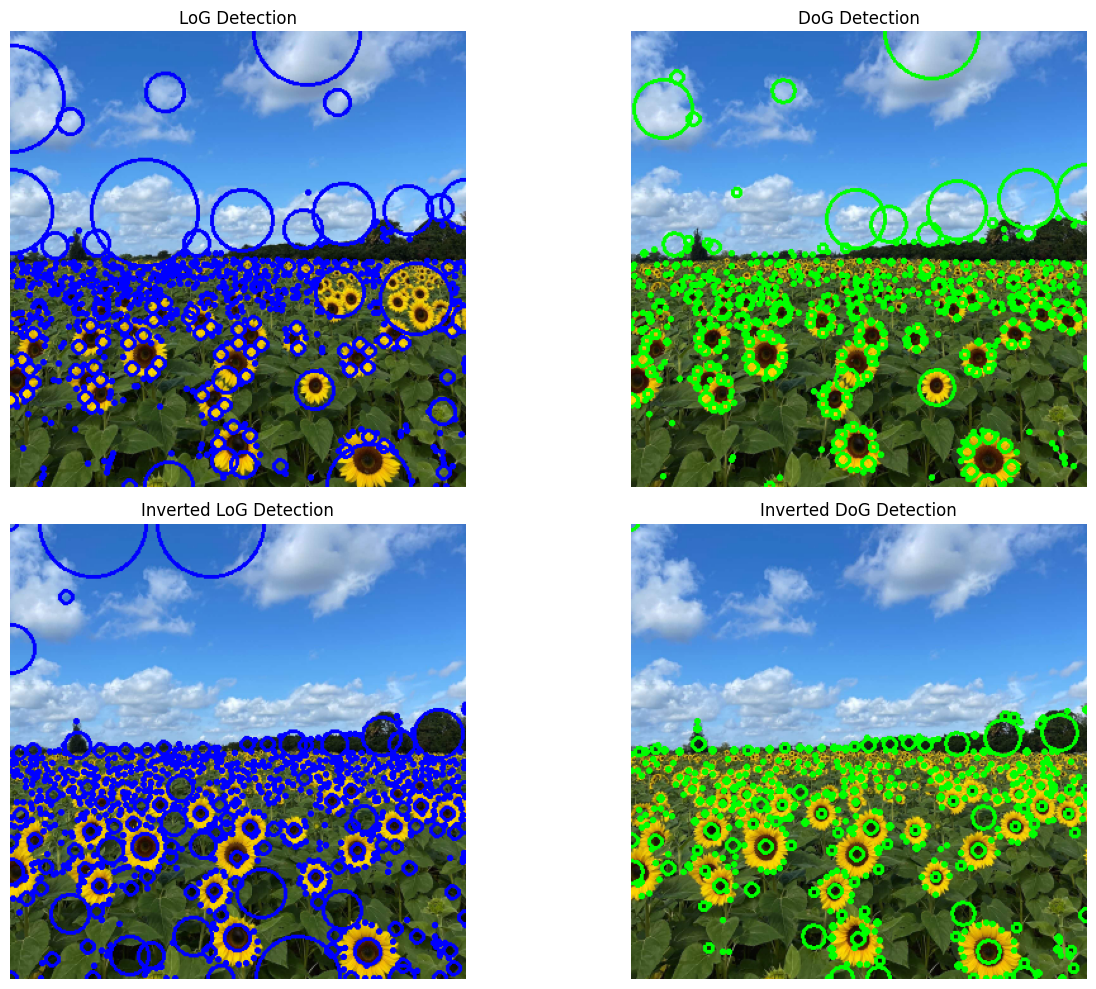

Sigma range: 1 to 30

LoG Results
Number of circles: 674
Circle 1: Center = (234.00, 0.00), Radius = 42.43, Sigma = 30.00
Circle 2: Center = (0.00, 53.00), Radius = 42.43, Sigma = 30.00
Circle 3: Center = (106.00, 143.00), Radius = 42.43, Sigma = 30.00
Circle 4: Center = (283.00, 359.00), Radius = 33.31, Sigma = 23.56
Circle 5: Center = (0.00, 142.00), Radius = 33.31, Sigma = 23.56

DoG Results
Number of circles: 556
Circle 1: Center = (237.00, 0.00), Radius = 37.96, Sigma = 26.84
Circle 2: Center = (257.00, 141.00), Radius = 23.73, Sigma = 16.78
Circle 3: Center = (359.00, 128.00), Radius = 23.73, Sigma = 16.78
Circle 4: Center = (313.00, 132.00), Radius = 23.73, Sigma = 16.78
Circle 5: Center = (25.00, 61.00), Radius = 23.73, Sigma = 16.78

Inverted LoG Results
Number of circles: 827
Circle 1: Center = (65.00, 0.00), Radius = 42.43, Sigma = 30.00
Circle 2: Center = (158.00, 0.00), Radius = 42.43, Sigma = 30.00
Circle 3: Center = (227.00, 359.00), Radius = 33.31, Sigma = 23.56
Circle 

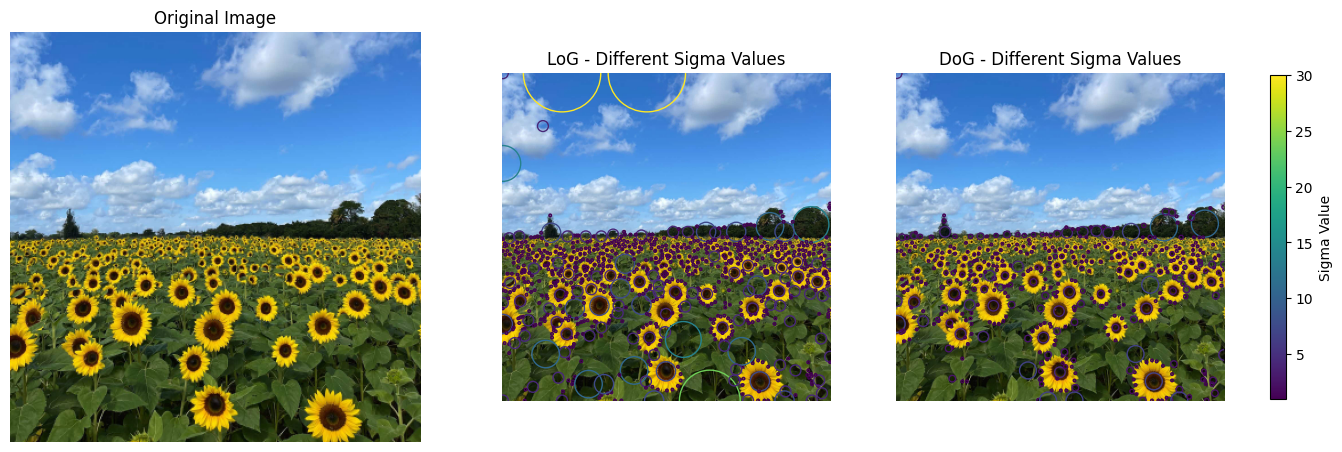

In [ ]:
img = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

gray_inv = cv.bitwise_not(gray)
min_sigma = 1
max_sigma = 30

log_blobs = blob_log(gray, min_sigma=min_sigma,max_sigma=max_sigma, num_sigma=10,threshold=0.1)

log_dark = blob_log(gray_inv, min_sigma=min_sigma,max_sigma=max_sigma, num_sigma=10,threshold=0.1)

dog_blobs = blob_dog(gray, min_sigma=min_sigma,max_sigma=max_sigma, threshold=0.1)

dog_dark = blob_dog(gray_inv, min_sigma=min_sigma,max_sigma=max_sigma, threshold=0.1)

def draw_circles(image, blobs, color):
    output = image.copy()

    for y, x, sigma in blobs:
        radius = int(sigma * np.sqrt(2))
        cv.circle(output, (int(x), int(y)),radius, color, 2)

    return output

result_log = draw_circles(img, log_blobs, (255, 0, 0))
result_dog = draw_circles(img, dog_blobs, (0, 255, 0))

result_log_dark = draw_circles(img, log_dark, (255, 0, 0))
result_dog_dark = draw_circles(img, dog_dark, (0, 255, 0))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

images = [result_log, result_dog,
          result_log_dark, result_dog_dark]

titles = ['LoG Detection', 'DoG Detection','Inverted LoG Detection', 'Inverted DoG Detection']

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

def largest_circles(blobs, method):
    print(f"\n{method}")
    print("Number of circles:", len(blobs))

    sorted_blobs = sorted(blobs, key=lambda b: b[2], reverse=True)

    for i, blob in enumerate(sorted_blobs[:5]):
        y, x, sigma = blob
        radius = sigma * np.sqrt(2)

        print(f"Circle {i+1}: Center = ({x:.2f}, {y:.2f}), "
              f"Radius = {radius:.2f}, Sigma = {sigma:.2f}")


print("Sigma range:", min_sigma, "to", max_sigma)

largest_circles(log_blobs, "LoG Results")
largest_circles(dog_blobs, "DoG Results")
largest_circles(log_dark, "Inverted LoG Results")
largest_circles(dog_dark, "Inverted DoG Results")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
axes[0].set_title("Original Image")
axes[0].axis('off')

cmap = plt.get_cmap('viridis')

for ax, blobs, title in zip(
    axes[1:],
    [log_dark, dog_dark],
    ["LoG - Different Sigma Values",
     "DoG - Different Sigma Values"]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

    for y, x, sigma in blobs:
        radius = sigma * np.sqrt(2)
        color = cmap((sigma - min_sigma) / (max_sigma - min_sigma))

        circle = Circle((x, y), radius,fill=False, color=color, linewidth=1)
        ax.add_patch(circle)

    ax.set_title(title)
    ax.axis('off')

norm = plt.Normalize(min_sigma, max_sigma)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes[1:], label="Sigma Value", shrink=0.7)

plt.show()


## Question 2: Manual RANSAC, line then circle

In [13]:
np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt , y0_gt = 2, 3 # Center
s = r/16
t = np.random.uniform(0, 2*np.pi , half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
X = np.vstack((X_circ , X_line )) # All points

In [ ]:
# Fit a line using total least squares
def fit_line(points):
    center = points.mean(axis=0)

    if np.max(np.linalg.norm(points-center, axis=1)) < 1e-10:
        return None

    _, _, V = np.linalg.svd(points-center)

    a, b = V[-1]
    d = a*center[0] + b*center[1]

    if d < 0:
        a, b, d = -a, -b, -d

    return np.array([a, b, d])

# Perpendicular distance to line
def line_error(points, model):
    a, b, d = model
    return np.abs(a*points[:, 0] + b*points[:, 1] - d)


# Find circle passing through three points
def fit_circle(points):
    p1, p2, p3 = points

    A = 2 * np.array([p2-p1, p3-p1])
    B = np.array([p2@p2-p1@p1, p3@p3-p1@p1])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1-center)

    return np.array([center[0], center[1], radius])


# Radial distance error
def circle_error(points, model):
    cx, cy, radius = model
    distances = np.linalg.norm(points - [cx, cy], axis=1)
    return np.abs(distances - radius)


# Manual RANSAC algorithm
def ransac(points, sample_size, fit_function, error_function,
           threshold, min_inliers, seed, iterations=2000):

    rng = np.random.default_rng(seed)

    best = None
    best_count = 0
    best_error = np.inf

    for i in range(iterations):

        ids = rng.choice(len(points), sample_size, replace=False)
        model = fit_function(points[ids])

        if model is None:
            continue

        errors = error_function(points, model)
        inliers = np.isfinite(errors) & (errors < threshold)

        count = int(inliers.sum())
        total_error = np.sum(errors[inliers]**2)

        if count >= min_inliers and (
            count > best_count or
            (count == best_count and total_error < best_error)
        ):
            best_count = count
            best_error = total_error

            best = {
                'sample': ids,
                'sample_model': model,
                'inliers': inliers
            }
    return best

In [ ]:

# Part (a): Line fitting
line = ransac(X, 2, fit_line, line_error,
              threshold=1.5, min_inliers=35, seed=42)

line_model = fit_line(X[line['inliers']])
line_mask = line_error(X, line_model) < 1.5

# Part (b): Remove line inliers
remaining_ids = np.where(~line_mask)[0]
remaining = X[remaining_ids]

# Fit circle using RANSAC
circle = ransac(remaining, 3, fit_circle, circle_error,
                threshold=1.25, min_inliers=25, seed=43)

# Improve circle using least squares
circle_points = remaining[circle['inliers']]

result = least_squares(
    lambda p: np.linalg.norm(circle_points-p[:2], axis=1)-p[2],
    x0=circle['sample_model'],
    bounds=([-np.inf, -np.inf, 1e-8],
            [np.inf, np.inf, np.inf])
)

circle_model = result.x

# Identify final circle inliers
circle_mask = np.zeros(len(X), dtype=bool)
circle_mask[remaining_ids] = (circle_error(remaining, circle_model) < 1.25)

print("Line (a, b, d):", np.round(line_model, 3))
print("Normal magnitude:", np.linalg.norm(line_model[:2]))
print("Line inliers:", line_mask.sum())

print("Circle (cx, cy, r):", np.round(circle_model, 3))
print("Circle inliers:", circle_mask.sum())

print("Line RMS error:",
      np.sqrt(np.mean(line_error(X[line_mask], line_model)**2)))

print("Circle RMS error:",np.sqrt(np.mean(circle_error(X[circle_mask], circle_model)**2)))


Line (a, b, d): [0.716 0.698 1.562]
Normal magnitude: 0.9999999999999999
Line inliers: 54
Circle (cx, cy, r): [1.949 2.988 9.892]
Circle inliers: 44
Line RMS error: 0.6754616681448892
Circle RMS error: 0.5358998310131629


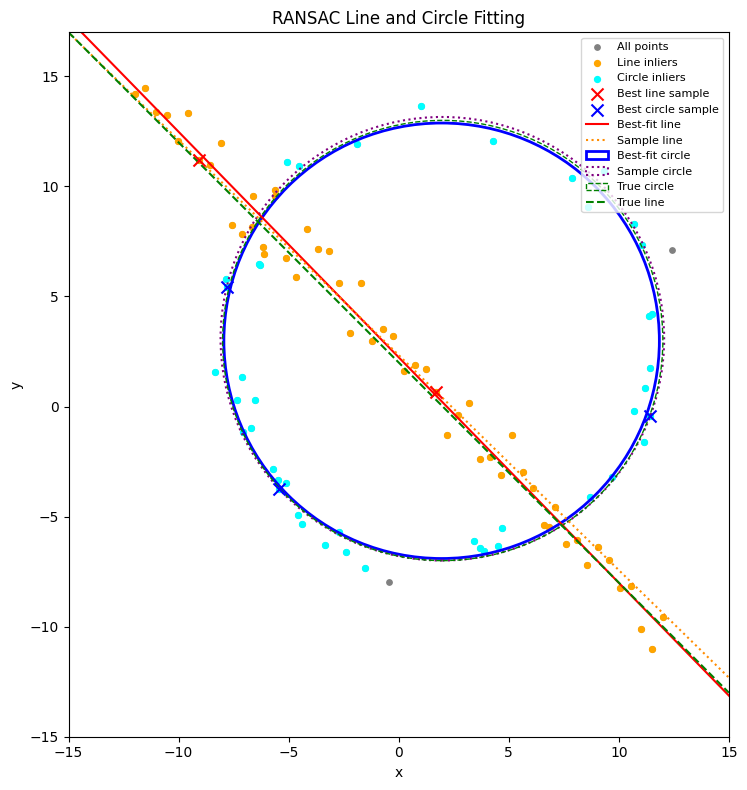

In [16]:

fig, ax = plt.subplots(figsize=(8, 8))

# All points
ax.scatter(X[:, 0], X[:, 1], s=15,
           color='gray', label='All points')

# Line inliers
ax.scatter(X[line_mask, 0], X[line_mask, 1],
           s=18, color='orange', label='Line inliers')

# Circle inliers
ax.scatter(X[circle_mask, 0], X[circle_mask, 1],
           s=18, color='cyan', label='Circle inliers')

# Sample points for line
ax.scatter(X[line['sample'], 0], X[line['sample'], 1],
           marker='x', s=75, color='red',
           label='Best line sample', zorder=5)

# Sample points for circle
ax.scatter(remaining[circle['sample'], 0],
           remaining[circle['sample'], 1],
           marker='x', s=75, color='blue',
           label='Best circle sample', zorder=5)


# Function to draw lines
def draw_line(model, color, style, name):
    a, b, d = model

    center = np.array([a, b]) * d
    direction = np.array([-b, a])

    pts = center + np.array([-25, 25])[:, None]*direction

    ax.plot(pts[:, 0], pts[:, 1],
            color=color, linestyle=style, label=name)


# Best-fit line
draw_line(line_model, 'red', '-', 'Best-fit line')

# Line from the best sample
draw_line(line['sample_model'], 'darkorange',
          ':', 'Sample line')

# Best-fit circle
ax.add_patch(Circle(
    circle_model[:2], circle_model[2],
    fill=False, edgecolor='blue',
    linewidth=2, label='Best-fit circle'
))

# Circle from best sample
ax.add_patch(Circle(
    circle['sample_model'][:2],
    circle['sample_model'][2],
    fill=False, edgecolor='purple',
    linestyle=':', linewidth=1.5,
    label='Sample circle'
))

# Ground truth circle
ax.add_patch(Circle(
    (x0_gt, y0_gt), r,
    fill=False, edgecolor='green',
    linestyle='--', label='True circle'
))

# Ground truth line
x_plot = np.array([-15, 15])
ax.plot(x_plot, m*x_plot+b, 'g--', label='True line')

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('RANSAC Line and Circle Fitting')
ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


In [18]:

circle_first = ransac(
    X, 3, fit_circle, circle_error,
    threshold=1.25,
    min_inliers=25,
    seed=44
)

print("Circle-first estimate:",
      np.round(circle_first['sample_model'], 3))

print("Circle-first inliers:",
      circle_first['inliers'].sum())


Circle-first estimate: [ 1.992  3.088 10.012]
Circle-first inliers: 58


## Question 3: planar homography and blending